# Experiment 3: Selection Methods
**Aim:** To implement basic selection methods for selecting suitable individuals from a population using Python.

**Theory:** Selection chooses parents for reproduction, favouring fitter individuals while keeping some diversity. Methods implemented: **Roulette-wheel**, **Tournament**, **Rank-based**, **Stochastic Universal Sampling (SUS)** and **Truncation**.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(7)
np.random.seed(7)

# Population of 10 individuals identified by index, with given fitness values
fitness = [5, 12, 3, 20, 8, 15, 1, 9, 25, 6]
population = [f"I{i}" for i in range(len(fitness))]
print(list(zip(population, fitness)))

[('I0', 5), ('I1', 12), ('I2', 3), ('I3', 20), ('I4', 8), ('I5', 15), ('I6', 1), ('I7', 9), ('I8', 25), ('I9', 6)]


## 1. Roulette-wheel (fitness-proportionate) selection

In [2]:
def roulette_selection(pop, fit, k):
    total = sum(fit)
    probs = [f / total for f in fit]
    chosen = []
    for _ in range(k):
        r = random.random()
        cum = 0
        for ind, p in zip(pop, probs):
            cum += p
            if r <= cum:
                chosen.append(ind)
                break
    return chosen

print(roulette_selection(population, fitness, 5))

['I3', 'I1', 'I7', 'I1', 'I5']


## 2. Tournament selection

In [3]:
def tournament_selection(pop, fit, k, tsize=3):
    chosen = []
    for _ in range(k):
        contenders = random.sample(range(len(pop)), tsize)
        winner = max(contenders, key=lambda i: fit[i])
        chosen.append(pop[winner])
    return chosen

print(tournament_selection(population, fitness, 5))

['I3', 'I1', 'I3', 'I8', 'I3']


## 3. Rank-based selection

In [4]:
def rank_selection(pop, fit, k):
    order = sorted(range(len(pop)), key=lambda i: fit[i])         # worst -> best
    ranks = [0] * len(pop)
    for r, idx in enumerate(order, start=1):
        ranks[idx] = r
    return random.choices(pop, weights=ranks, k=k)

print(rank_selection(population, fitness, 5))

['I6', 'I5', 'I1', 'I5', 'I0']


## 4. Stochastic Universal Sampling (SUS)

In [5]:
def sus_selection(pop, fit, k):
    total = sum(fit)
    step = total / k
    start = random.uniform(0, step)
    pointers = [start + i * step for i in range(k)]
    chosen, cum, idx = [], fit[0], 0
    for p in pointers:
        while cum < p:
            idx += 1
            cum += fit[idx]
        chosen.append(pop[idx])
    return chosen

print(sus_selection(population, fitness, 5))

['I0', 'I3', 'I4', 'I7', 'I8']


## 5. Truncation selection

In [6]:
def truncation_selection(pop, fit, k):
    order = sorted(range(len(pop)), key=lambda i: fit[i], reverse=True)
    return [pop[i] for i in order[:k]]

print(truncation_selection(population, fitness, 5))

['I8', 'I3', 'I5', 'I1', 'I7']


## 6. Comparing selection pressure
Each method selects 5000 individuals; we count how often each individual is picked.

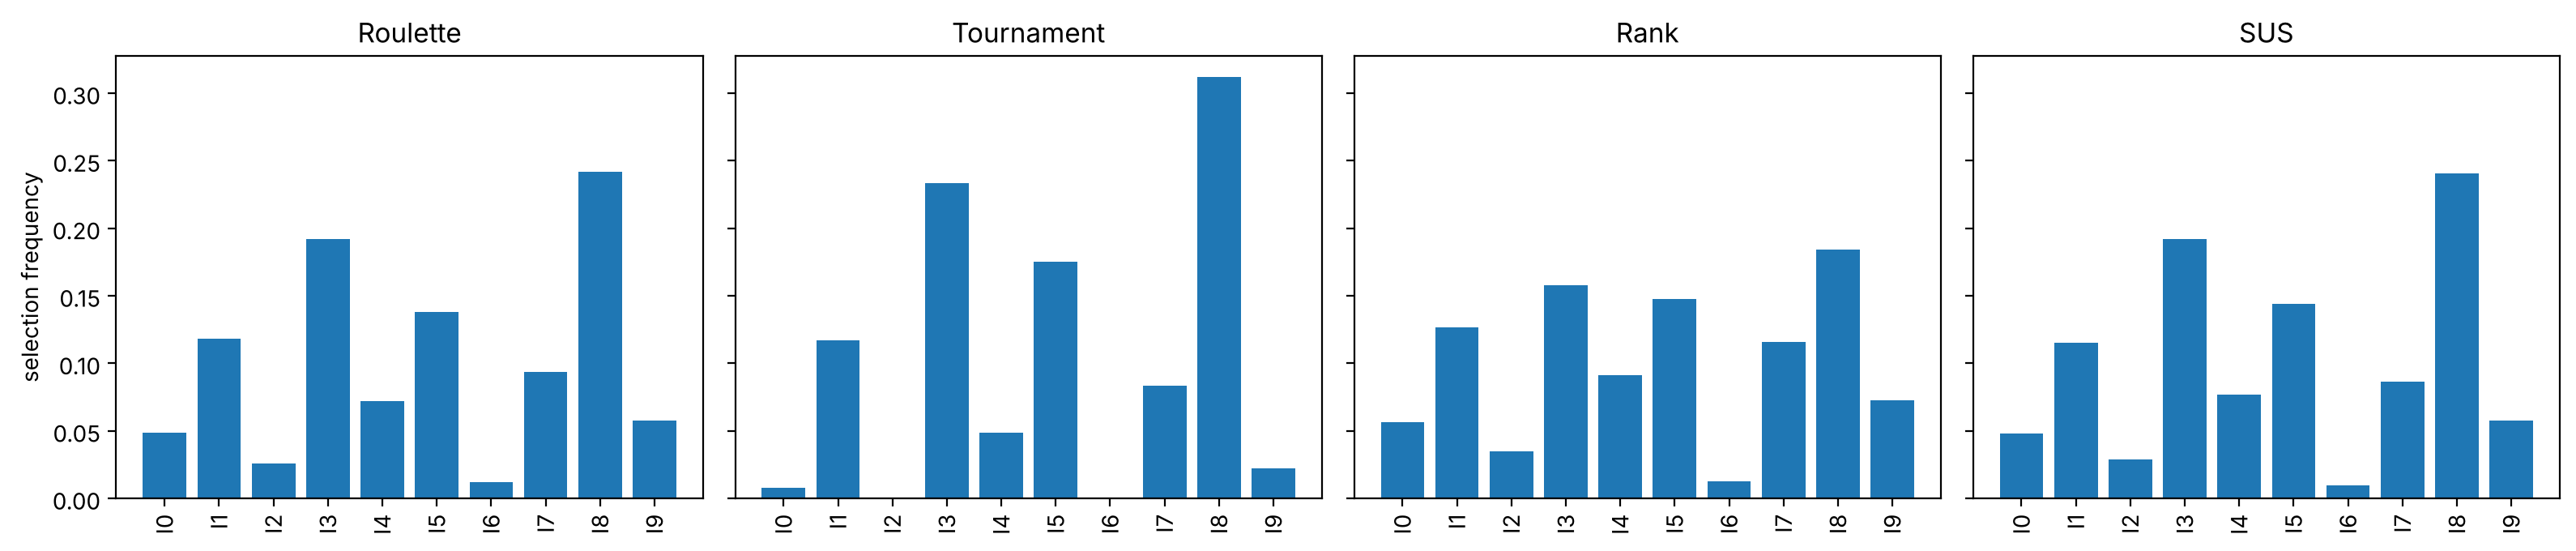

In [7]:
methods = {
    "Roulette":   roulette_selection,
    "Tournament": tournament_selection,
    "Rank":       rank_selection,
    "SUS":        sus_selection,
}
N = 5000
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (name, fn) in zip(axes, methods.items()):
    picks = fn(population, fitness, N)
    counts = [picks.count(p) / N for p in population]
    ax.bar(population, counts)
    ax.set_title(name); ax.tick_params(axis='x', rotation=90)
axes[0].set_ylabel("selection frequency")
plt.tight_layout(); plt.show()

## Conclusion
All five selection operators were implemented. Roulette and SUS are proportional to fitness, rank selection reduces dominance of very fit individuals, tournament selection gives tunable pressure through the tournament size, and truncation is the most elitist.